Optimal max_depth: 17 with Accuracy: 75.92%


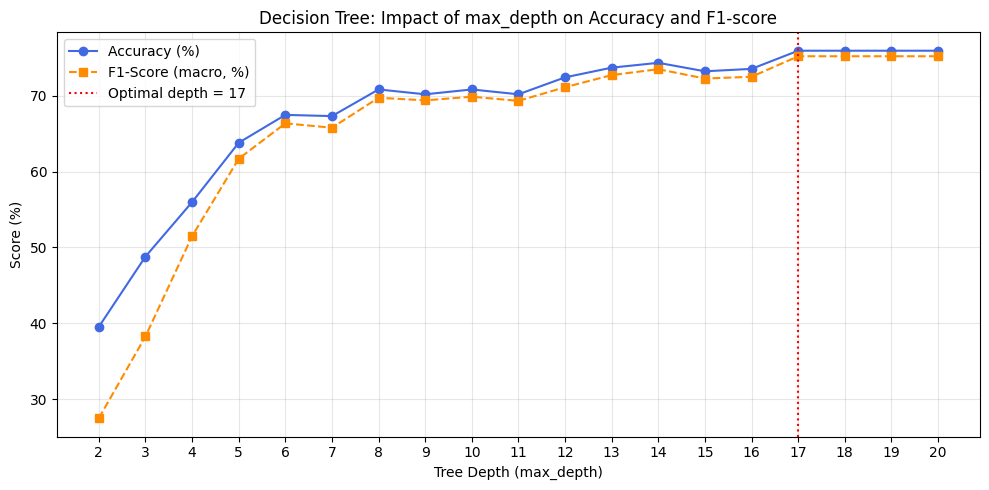

Hold-out Accuracy: 75.92%
Hold-out F1-Score: 75.19%
10-Fold CV Mean Accuracy: 76.23%
10-Fold CV Standard Deviation: 0.0152


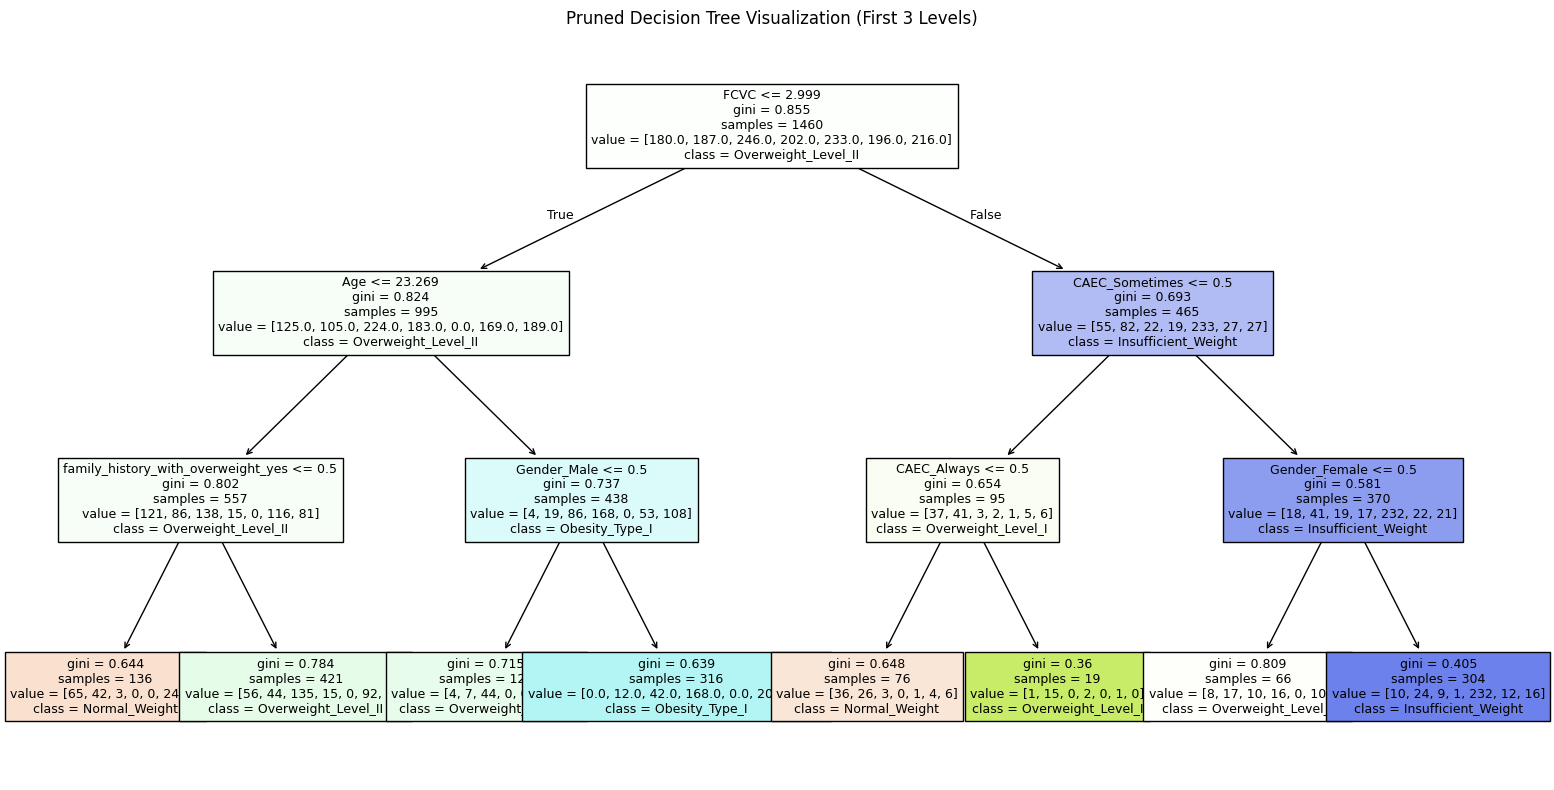

In [7]:
# ============================================================
# PART 1: IMPORTS AND CONFIGURATION
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, f1_score

RANDOM_STATE = 42

# ============================================================
# PART 2: DATA LOADING AND PREPROCESSING
# ============================================================
df = pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv')
df = df.drop_duplicates()

# Prevent Data Leakage
X_dt = df.drop(columns=['NObeyesdad', 'Weight', 'Height'])
y_dt = df['NObeyesdad']
X_dt_encoded = pd.get_dummies(X_dt, dtype=int)

# ============================================================
# PART 3: TRAIN / TEST SPLIT (HOLD-OUT METHOD)
# ============================================================
x_train, x_test, y_train, y_test = train_test_split(
    X_dt_encoded, y_dt, test_size=0.30, random_state=RANDOM_STATE
)

# ============================================================
# PART 4: EVALUATING VARYING TREE DEPTHS (TASK 4a)
# ============================================================
depths = range(2, 21)
acc_scores = []
f1_scores = []

for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    clf.fit(x_train, y_train)
    y_pred_d = clf.predict(x_test)
    acc_scores.append(accuracy_score(y_test, y_pred_d) * 100)
    f1_scores.append(f1_score(y_test, y_pred_d, average='macro') * 100)

best_idx = np.argmax(acc_scores)
best_depth = list(depths)[best_idx]
print(f"Optimal max_depth: {best_depth} with Accuracy: {acc_scores[best_idx]:.2f}%")

# Line Plot: Depth vs Performance
plt.figure(figsize=(10, 5))
plt.plot(depths, acc_scores, marker='o', color='royalblue', label='Accuracy (%)')
plt.plot(depths, f1_scores, marker='s', color='darkorange', linestyle='--', label='F1-Score (macro, %)')
plt.axvline(x=best_depth, color='red', linestyle=':', label=f'Optimal depth = {best_depth}')
plt.title('Decision Tree: Impact of max_depth on Accuracy and F1-score')
plt.xlabel('Tree Depth (max_depth)')
plt.ylabel('Score (%)')
plt.xticks(depths)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('decision_tree_depth_impact.png', dpi=300)
plt.show()

# ============================================================
# PART 5: OPTIMAL DECISION TREE MODEL
# ============================================================
optimal_tree = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=1, random_state=RANDOM_STATE)
optimal_tree.fit(x_train, y_train)
y_pred_final = optimal_tree.predict(x_test)

print(f"Hold-out Accuracy: {accuracy_score(y_test, y_pred_final) * 100:.2f}%")
print(f"Hold-out F1-Score: {f1_score(y_test, y_pred_final, average='macro') * 100:.2f}%")

# ============================================================
# PART 6: K-FOLD CROSS-VALIDATION (TASK 3)
# ============================================================
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(optimal_tree, X_dt_encoded, y_dt, cv=skf, scoring='accuracy')

print(f"10-Fold CV Mean Accuracy: {cv_scores.mean() * 100:.2f}%")
print(f"10-Fold CV Standard Deviation: {cv_scores.std():.4f}")

# ============================================================
# PART 7: PRUNED TREE VISUALIZATION (OPTIONAL TASK 5a)
# ============================================================
pruned_tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
pruned_tree.fit(x_train, y_train)

plt.figure(figsize=(16, 8))
plot_tree(
    pruned_tree,
    feature_names=X_dt_encoded.columns,
    class_names=y_dt.unique(),
    filled=True,
    fontsize=9
)
plt.title('Pruned Decision Tree Visualization (First 3 Levels)')
plt.tight_layout()
plt.show()